<a href="https://colab.research.google.com/github/mustafaSal95/AgentDebateArena/blob/main/PMPD_Experiments_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PMPD – Memory Priority Scheduling: Simulation Core, Synthetic & Real-Data Experiments

Covers project scope items 1–4:

1. **PMPD core** – K-means PM clustering + CPU:memory-balance VM deployment rule, inside one reusable simulator.
2. **Synthetic experiment** – PMs/VMs built from the paper's parameters; VM-count sweep and minimum-utilisation-threshold sweep.
3. **Real-data experiment** – Alibaba Cluster Trace v2018 (`batch_instance`), same core and metrics.
4. **First-Fit baseline** – run through both experiments with the same VM stream.

**Run order:** run all cells top to bottom. The synthetic part needs no files. The real-data part needs `batch_instance.tar.gz` (a partial download is fine) or the extracted csv – set the path in the *Real-data configuration* cell; if the file is missing that section is skipped with a message.

Dependencies: `numpy pandas scikit-learn matplotlib` only.

## Modelling assumptions (state these in the report)

The paper does not publish its CloudSim configuration, so these choices are ours:

| Item | Choice |
|---|---|
| PM types | 18 cores/72 GB, 64 cores/256 GB, 16 cores/64 GB (paper Table IX); 200 PMs of each type, shuffled |
| VMs | 1, 2 or 4 vCPUs; memory = vCPUs × {2, 4, 8} GB (ratios 1:2, 1:4, 1:8); durations uniform 500–5000 s; Poisson arrivals, 1 VM/s |
| Time | Event-driven simulated time; a VM releases its resources at `arrival + duration` |
| Sleep | A PM with no VMs sleeps and draws no power; it is woken only when no active PM fits the VM |
| Power (Eq. 4) | Linear in CPU use: idle = 50 + 1.0·cores W, peak = 100 + 4.0·cores W |
| PM utilisation | mean of CPU and memory utilisation |
| Light-load time (Eq. 1) | total PM time active with utilisation below the minimum-utilisation threshold |
| Avg CPU / memory util (Eq. 2–3) | time-weighted over active PM time |
| Dynamic clustering | K-means (k = 3, scikit-learn, warm-started) refit every 25 deployments on active PMs' (CPU util, mem util); every VM re-labels PMs against the latest centres |
| Rule 2 – cluster choice | cluster whose imbalance the VM corrects best: smallest \|CPU util − mem util\| after adding the VM |
| Rule 2 – PM choice | prefer PMs below the utilisation threshold (our addition, since the paper does not say how the threshold enters placement), then the PM whose remaining time is closest to the VM's duration |
| First-Fit | first active PM in list order that fits; otherwise wake the first sleeping PM that fits |
| PM wake-up (both) | first sleeping PM in list order that fits – identical for both algorithms so only the placement logic differs |

In [2]:
import heapq, warnings, time, os, tarfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

## 1. Simulation core
### PM pool, power model and synthetic generators

In [3]:
# ---------------- PM / power model ----------------
PM_TYPES = [(18, 72), (64, 256), (16, 64)]      # (cores, mem) from paper Table IX

def power_model(cores):
    """Linear power model (assumption, not from paper): idle and peak watts grow with core count."""
    cores = np.asarray(cores, float)
    return 50 + 1.0 * cores, 100 + 4.0 * cores   # (P_idle, P_peak)

def make_synthetic_pms(n_per_type, seed=0):
    caps = [t for t in PM_TYPES for _ in range(n_per_type)]
    order = np.random.default_rng(seed).permutation(len(caps))
    caps = np.array(caps, float)[order]
    return caps[:, 0], caps[:, 1]

def make_synthetic_vms(n, seed=0, rate=1.0, dur_range=(500, 5000)):
    rng = np.random.default_rng(seed)
    arr = np.cumsum(rng.exponential(1.0 / rate, n))
    cpu = rng.choice([1, 2, 4], n).astype(float)
    mem = cpu * rng.choice([2, 4, 8], n)               # GB per vCPU: 1:2, 1:4, 1:8
    dur = rng.integers(dur_range[0], dur_range[1] + 1, n).astype(float)
    return dict(arr=arr, cpu=cpu, mem=mem, dur=dur)

### Data-center state and metrics (Eq. 1–4)

In [4]:
class DataCenter:
    def __init__(self, cpu_cap, mem_cap, thr):
        n = len(cpu_cap)
        self.cpu_cap = np.asarray(cpu_cap, float); self.mem_cap = np.asarray(mem_cap, float)
        self.p_idle, self.p_peak = power_model(self.cpu_cap)
        self.thr = thr
        z = lambda: np.zeros(n)
        self.cpu_used, self.mem_used, self.busy_until, self.last_t = z(), z(), z(), z()
        self.nvm = np.zeros(n, int)
        self.active_time, self.light_time = z(), z()
        self.area_cpu, self.area_mem, self.energy_j = z(), z(), z()
        self.ever_active = np.zeros(n, bool)
        self.heap, self.seq = [], 0
        self.n_active = self.peak_active = 0

    def fits(self, c, m):
        return ((self.cpu_cap - self.cpu_used) >= c - 1e-9) & ((self.mem_cap - self.mem_used) >= m - 1e-9)

    def _settle(self, i, t):
        dt = t - self.last_t[i]
        if dt > 0 and self.nvm[i] > 0:
            uc = self.cpu_used[i] / self.cpu_cap[i]; um = self.mem_used[i] / self.mem_cap[i]
            self.active_time[i] += dt
            self.area_cpu[i] += uc * dt; self.area_mem[i] += um * dt
            if (uc + um) / 2 < self.thr: self.light_time[i] += dt
            self.energy_j[i] += (self.p_idle[i] + (self.p_peak[i] - self.p_idle[i]) * uc) * dt
        self.last_t[i] = t

    def release_until(self, t):
        while self.heap and self.heap[0][0] <= t:
            end, _, i, c, m = heapq.heappop(self.heap)
            self._settle(i, end)
            self.cpu_used[i] -= c; self.mem_used[i] -= m; self.nvm[i] -= 1
            if self.nvm[i] == 0:                      # PM goes to sleep
                self.cpu_used[i] = self.mem_used[i] = self.busy_until[i] = 0.0
                self.n_active -= 1

    def place(self, i, c, m, t, end):
        assert self.cpu_used[i] + c <= self.cpu_cap[i] + 1e-6 and self.mem_used[i] + m <= self.mem_cap[i] + 1e-6
        self._settle(i, t)
        if self.nvm[i] == 0:
            self.n_active += 1; self.peak_active = max(self.peak_active, self.n_active); self.ever_active[i] = True
        self.cpu_used[i] += c; self.mem_used[i] += m; self.nvm[i] += 1
        self.busy_until[i] = max(self.busy_until[i], end)
        self.seq += 1
        heapq.heappush(self.heap, (end, self.seq, i, c, m))

    def metrics(self):
        ta = self.active_time.sum()
        return dict(light_load_time_s=self.light_time.sum(),
                    avg_cpu_util=self.area_cpu.sum() / ta,
                    avg_mem_util=self.area_mem.sum() / ta,
                    energy_kwh=self.energy_j.sum() / 3.6e6,
                    active_pm_hours=ta / 3600, peak_active_pms=self.peak_active,
                    pms_used=int(self.ever_active.sum()))

### Placement policies – First-Fit baseline and PMPD (Rule 1 + Rule 2)

In [5]:
# ---------------- policies ----------------
def _wake_first(dc, fits):
    idx = np.flatnonzero(fits & (dc.nvm == 0))
    return int(idx[0]) if idx.size else -1

class FirstFit:
    name = "First-Fit"
    def choose(self, dc, c, m, dur, t):
        fits = dc.fits(c, m)
        idx = np.flatnonzero(fits & (dc.nvm > 0))      # first active PM (list order) that fits
        return int(idx[0]) if idx.size else _wake_first(dc, fits)

class PMPD:
    name = "PMPD"
    def __init__(self, k=3, refit_every=25, use_threshold=True, seed=0):
        self.k, self.refit_every, self.use_thr, self.seed = k, refit_every, use_threshold, seed
        self.centers, self.since, self.refits = None, 0, 0

    def _refit(self, X):
        k = min(self.k, len(X))
        if self.centers is not None and len(self.centers) == k:
            km = KMeans(k, init=self.centers, n_init=1, max_iter=10)           # warm start
        else:
            km = KMeans(k, init="k-means++", n_init=3, max_iter=20, random_state=self.seed)
        self.centers = km.fit(X).cluster_centers_; self.since = 0; self.refits += 1

    def choose(self, dc, c, m, dur, t):
        fits = dc.fits(c, m)
        act = np.flatnonzero(dc.nvm > 0)
        if act.size and fits[act].any():
            uc = dc.cpu_used[act] / dc.cpu_cap[act]; um = dc.mem_used[act] / dc.mem_cap[act]
            X = np.c_[uc, um]
            # Rule 1: dynamic K-means over active PMs on (CPU util, mem util); periodic refit, relabel every call
            if self.centers is None or self.since >= self.refit_every or len(self.centers) != min(self.k, len(X)):
                self._refit(X)
            self.since += 1
            labels = ((X[:, None, :] - self.centers[None]) ** 2).sum(2).argmin(1)
            # Rule 2a: pick the cluster whose imbalance this VM corrects best (smallest |CPU util - mem util| after adding it)
            scores = []
            for j in np.unique(labels):
                mem_j = labels == j
                post = abs((uc[mem_j].mean() + c / dc.cpu_cap[act][mem_j].mean())
                           - (um[mem_j].mean() + m / dc.mem_cap[act][mem_j].mean()))
                scores.append((post, j))
            fit_act = fits[act]
            for _, j in sorted(scores):
                cand = np.flatnonzero((labels == j) & fit_act)
                if cand.size:
                    # Rule 2b: prefer PMs below the minimum-utilisation threshold, then closest remaining time
                    if self.use_thr:
                        low = ((uc[cand] + um[cand]) / 2) < dc.thr
                        if low.any(): cand = cand[low]
                    pm = act[cand]
                    rt = np.maximum(dc.busy_until[pm] - t, 0.0)
                    return int(pm[np.argmin(np.abs(rt - dur))])
        return _wake_first(dc, fits)

### Shared simulation loop (used by both algorithms and both datasets)

In [17]:


def simulate(vms, cpu_cap, mem_cap, policy, thr=0.6):
    dc = DataCenter(cpu_cap, mem_cap, thr)
    unplaced = 0
    for t, c, m, d in zip(vms["arr"].tolist(), vms["cpu"].tolist(), vms["mem"].tolist(), vms["dur"].tolist()):
        dc.release_until(t)
        i = policy.choose(dc, c, m, d, t)
        if i < 0: unplaced += 1; continue
        dc.place(i, c, m, t, t + d)
    dc.release_until(float("inf"))
    assert dc.n_active == 0 and np.allclose(dc.cpu_used, 0) and np.allclose(dc.mem_used, 0)
    out = dc.metrics(); out["unplaced_vms"] = unplaced; out["acceptance_rate"] = 1 - unplaced / len(vms["arr"])
    return out

### Sanity check
Tiny hand-checkable workload: both policies must place every VM without over-committing any PM and end with all PMs asleep.

In [7]:
tiny = dict(arr=np.array([0., 1, 2, 3, 4, 5]), cpu=np.array([2., 2, 4, 1, 1, 2]),
            mem=np.array([8., 16, 16, 8, 4, 8]), dur=np.array([100., 50, 200, 80, 120, 60]))
for pol in (FirstFit(), PMPD()):
    r = simulate(tiny, [16, 16, 16], [64, 64, 64], pol, thr=0.6)
    assert r["unplaced_vms"] == 0
    print(f"{pol.name:10s} unplaced={r['unplaced_vms']} PMs used={r['pms_used']} energy={r['energy_kwh']:.4f} kWh")
print("sanity checks passed")

First-Fit  unplaced=0 PMs used=1 energy=0.0061 kWh
PMPD       unplaced=0 PMs used=1 energy=0.0061 kWh
sanity checks passed


## 2. Synthetic experiment (paper-style parameters)
Metrics: light-load PM time, average CPU utilisation, average memory utilisation, total energy. Each point is the mean over 3 random seeds (shaded band = ±1 std).

In [8]:
SEEDS      = [0, 1, 2]
N_VMS      = [10_000, 20_000, 30_000, 40_000, 50_000]   # paper Table X
THRESHOLDS = [0.50, 0.60, 0.70]                         # paper Table X
DEFAULT_THR, SWEEP_N = 0.60, 50_000
PMS_PER_TYPE = 200
METRICS = [("light_load_time_s", "Light-load PM time (s)"), ("avg_cpu_util", "Average CPU utilisation"),
           ("avg_mem_util", "Average memory utilisation"), ("energy_kwh", "Total energy (kWh)")]

def run_synthetic(n, thr, seed):
    cpu, mem = make_synthetic_pms(PMS_PER_TYPE, seed)
    vms = make_synthetic_vms(n, seed)               # same VM stream for both algorithms
    rows = []
    for pol in (FirstFit(), PMPD(seed=seed)):
        r = simulate(vms, cpu, mem, pol, thr); r.update(algorithm=pol.name, n_vms=n, threshold=thr, seed=seed); rows.append(r)
    return rows

def plot_sweep(df, x, xlabel, title):
    fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
    for ax, (col, lab) in zip(axes, METRICS):
        for alg, mk in (("First-Fit", "o--"), ("PMPD", "s-")):
            g = df[df.algorithm == alg].groupby(x)[col].agg(["mean", "std"]).fillna(0)
            ax.plot(g.index, g["mean"], mk, label=alg); ax.fill_between(g.index, g["mean"] - g["std"], g["mean"] + g["std"], alpha=.15)
        ax.set_xlabel(xlabel); ax.set_title(lab, fontsize=10); ax.grid(alpha=.3)
    axes[0].legend(); fig.suptitle(title, y=1.03); plt.tight_layout(); plt.show()

def improvement(df, x):
    m = df.groupby(["algorithm", x])[[c for c, _ in METRICS]].mean()
    ff, pm = m.loc["First-Fit"], m.loc["PMPD"]
    out = pd.DataFrame({"light-load time reduction %": 100 * (ff.light_load_time_s - pm.light_load_time_s) / ff.light_load_time_s,
                        "CPU util change (pp)": 100 * (pm.avg_cpu_util - ff.avg_cpu_util),
                        "memory util change (pp)": 100 * (pm.avg_mem_util - ff.avg_mem_util),
                        "energy reduction %": 100 * (ff.energy_kwh - pm.energy_kwh) / ff.energy_kwh})
    return out.round(2)

### 2a. VM-count sweep

done in 193s; unplaced VMs: 0


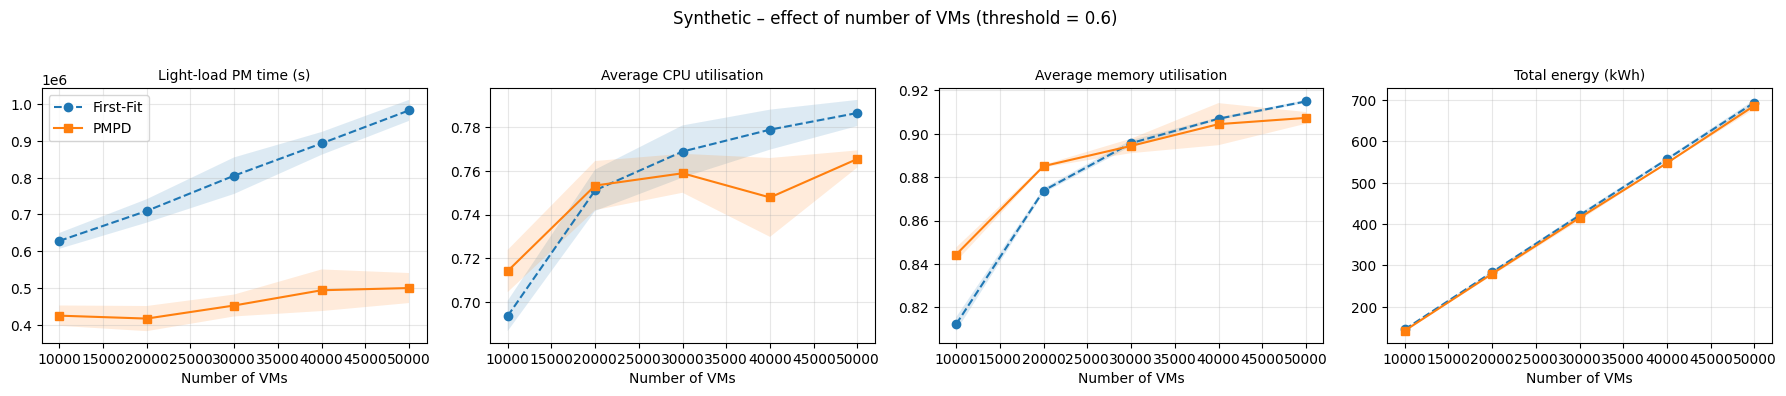

,light-load time reduction %,CPU util change (pp),memory util change (pp),energy reduction %
n_vms,,,,
10000,32.28,2.05,3.21,2.21
20000,41.17,0.22,1.13,1.38
30000,43.75,-0.99,-0.13,1.40
40000,44.63,-3.10,-0.25,1.65
50000,49.07,-2.10,-0.76,1.08


In [9]:
t0 = time.time()
vm_sweep = pd.DataFrame([r for n in N_VMS for s in SEEDS for r in run_synthetic(n, DEFAULT_THR, s)])
print(f"done in {time.time()-t0:.0f}s; unplaced VMs: {int(vm_sweep.unplaced_vms.sum())}")
plot_sweep(vm_sweep, "n_vms", "Number of VMs", "Synthetic – effect of number of VMs (threshold = 0.6)")
improvement(vm_sweep, "n_vms")

### 2b. Minimum-utilisation-threshold sweep

done in 188s; unplaced VMs: 0


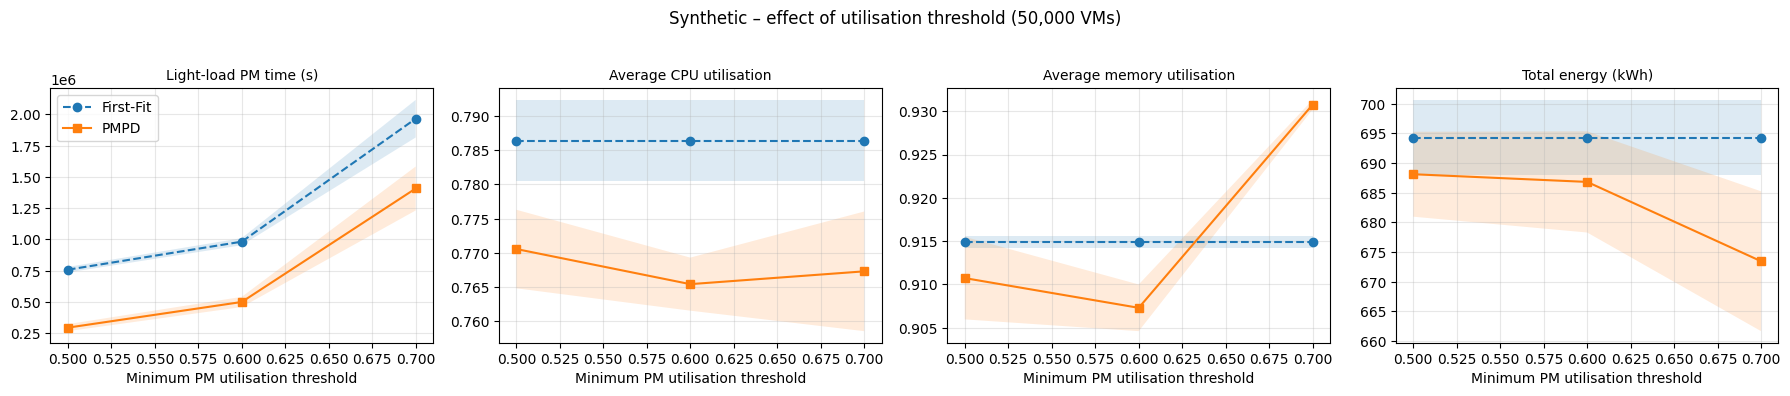

,light-load time reduction %,CPU util change (pp),memory util change (pp),energy reduction %
threshold,,,,
0.5,61.10,-1.58,-0.42,0.89
0.6,49.07,-2.10,-0.76,1.08
0.7,28.39,-1.91,1.59,3.00


In [10]:
t0 = time.time()
thr_sweep = pd.DataFrame([r for th in THRESHOLDS for s in SEEDS for r in run_synthetic(SWEEP_N, th, s)])
print(f"done in {time.time()-t0:.0f}s; unplaced VMs: {int(thr_sweep.unplaced_vms.sum())}")
plot_sweep(thr_sweep, "threshold", "Minimum PM utilisation threshold", f"Synthetic – effect of utilisation threshold ({SWEEP_N:,} VMs)")
improvement(thr_sweep, "threshold")

## 3. Real-data experiment (Alibaba Cluster Trace v2018, `batch_instance`)

Each **Terminated** instance becomes one VM request: arrival = `start_time`, duration = `end_time − start_time`, CPU = `cpu_avg / 100` cores, memory = `mem_avg` (normalised % of one machine's memory). PMs are homogeneous 96-core machines with normalised memory 100, as in `machine_meta`. **Verify these units against the trace's schema document** before reporting results.

In [15]:
# ---- Real-data configuration ----
BATCH_INSTANCE_PATH = "batch_instance.tar.gz" # full or partially downloaded .tar.gz, or a plain csv
MACHINE_META_PATH   = None                    # optional: path to machine_meta csv to read PM spec from
REAL_NROWS          = 1_000_000               # rows read from the file
REAL_VMS_PER_WINDOW = 50_000                  # VMs simulated in each window
REAL_WINDOW_STARTS  = [0, 100_000, 200_000]   # window offsets, counted in VMs ordered by start_time; a window with too few VMs is skipped
DEMAND              = "avg"                   # "avg" or "max" columns used as VM demand
REAL_THRS           = [0.2, 0.3, 0.6]         # light-load thresholds reported (avg utilisation on this trace is low)
POOL_HEADROOM       = 1.2                     # first guess for pool size = peak concurrent demand x this
PM_CPU, PM_MEM      = 96.0, 100.0             # default PM spec (cores, normalised memory)

def extract_head(path, nrows, out_csv):
    """Stream the first `nrows` lines of the csv inside a .tar.gz (or plain csv) into out_csv.
    Works on complete OR partially downloaded archives: it never seeks to the end, and the
    last line is dropped if the archive stops mid-line."""
    n, prev = 0, None
    with open(out_csv, "wb") as out:
        try:
            if path.endswith((".tar.gz", ".tgz")):
                with tarfile.open(path, "r|gz") as tar:
                    for member in tar:
                        if not member.isfile(): continue
                        for line in tar.extractfile(member):
                            if prev is not None: out.write(prev); n += 1
                            prev = line
                            if n + 1 >= nrows: break
                        break
            else:
                with open(path, "rb") as f:
                    for line in f:
                        if prev is not None: out.write(prev); n += 1
                        prev = line
                        if n + 1 >= nrows: break
            if prev is not None and prev.endswith(b"\n"): out.write(prev); n += 1   # last line complete
        except (EOFError, tarfile.ReadError, OSError):
            pass                                                                   # archive ended early
    return n

HEAD_CSV = "batch_instance_head.csv"      # local copy of the first REAL_NROWS rows (created below)

BI_COLS = ["instance_name", "task_name", "job_name", "task_type", "status", "start_time", "end_time",
           "machine_id", "seq_no", "total_seq_no", "cpu_avg", "cpu_max", "mem_avg", "mem_max"]

if MACHINE_META_PATH and os.path.exists(MACHINE_META_PATH):
    meta = pd.read_csv(MACHINE_META_PATH, names=["machine_id", "time_stamp", "fd1", "fd2", "cpu_num", "mem_size", "status"])
    meta = meta.drop_duplicates("machine_id")
    PM_CPU, PM_MEM = float(meta.cpu_num.mode()[0]), float(meta.mem_size.mode()[0])
print("PM spec used:", PM_CPU, "cores,", PM_MEM, "memory units")

def load_real_vms(path, nrows, demand="avg"):
    """Clean the trace and return ALL usable VMs sorted by start_time (windows are cut later)."""
    df = pd.read_csv(path, names=BI_COLS, usecols=["status", "start_time", "end_time", "cpu_avg", "cpu_max", "mem_avg", "mem_max"], nrows=nrows)
    log = [("rows loaded", len(df))]
    df = df[df.status == "Terminated"]; log.append(("status == Terminated", len(df)))
    df = df.dropna(subset=["start_time", "end_time", f"cpu_{demand}", f"mem_{demand}"]); log.append(("no missing time/cpu/mem", len(df)))
    df = df.assign(dur=df.end_time - df.start_time, cpu=df[f"cpu_{demand}"] / 100.0, mem=df[f"mem_{demand}"])
    df = df[(df.dur > 0) & (df.cpu > 0) & (df.mem > 0)]; log.append(("duration, cpu, mem > 0", len(df)))
    df = df[(df.cpu <= PM_CPU) & (df.mem <= PM_MEM)]; log.append(("fits on one PM", len(df)))
    df = df.sort_values("start_time")
    allv = dict(start=df.start_time.to_numpy(float), cpu=df.cpu.to_numpy(float), mem=df.mem.to_numpy(float), dur=df.dur.to_numpy(float))
    return allv, pd.DataFrame(log, columns=["cleaning step", "rows remaining"])

def slice_window(allv, skip, n):
    """n consecutive VMs starting at offset `skip`; arrivals re-zeroed. None if fewer than n/2 VMs are available."""
    sl = slice(skip, skip + n); st = allv["start"][sl]
    if len(st) < max(1, n // 2): return None
    return dict(arr=st - st[0], cpu=allv["cpu"][sl], mem=allv["mem"][sl], dur=allv["dur"][sl])

REAL_READY = os.path.exists(BATCH_INSTANCE_PATH)
if REAL_READY:
    n_got = extract_head(BATCH_INSTANCE_PATH, REAL_NROWS, HEAD_CSV)
    print(f"extracted {n_got:,} rows from {BATCH_INSTANCE_PATH}" + ("  (archive holds fewer than REAL_NROWS rows - partial download?)" if n_got < REAL_NROWS else ""))
    real_all, real_log = load_real_vms(HEAD_CSV, REAL_NROWS, DEMAND)
    print(real_log.to_string(index=False))
    print(f"\nusable VMs: {len(real_all['cpu']):,} | trace span covered: {(real_all['start'].max() - real_all['start'].min())/3600:.1f} h")
    display(pd.DataFrame({k: real_all[k] for k in ("cpu", "mem", "dur")}).describe().round(3))
else:
    print(f"'{BATCH_INSTANCE_PATH}' not found - set BATCH_INSTANCE_PATH above; real-data section skipped.")


PM spec used: 96.0 cores, 100.0 memory units
extracted 1,000,000 rows from batch_instance.tar.gz
          cleaning step  rows remaining
            rows loaded         1000000
   status == Terminated          991565
no missing time/cpu/mem          944293
 duration, cpu, mem > 0          907962
         fits on one PM          907962

usable VMs: 907,962 | trace span covered: 167.9 h


,cpu,mem,dur
count,907962.000,907962.000,907962.000
mean,0.625,0.129,48.200
std,0.335,0.264,292.767
min,0.010,0.010,1.000
25%,0.360,0.030,5.000
50%,0.700,0.050,17.000
75%,0.870,0.110,47.000
max,18.790,21.940,43817.000


window 0 | VMs 0-50,000 | span 10.1 h | peak demand 3237 cores, 1895 mem units -> pool 41 PMs
   done in 49s
window 1 | VMs 100,000-150,000 | span 10.6 h | peak demand 2201 cores, 925 mem units -> pool 28 PMs
   done in 45s
window 2 | VMs 200,000-250,000 | span 9.6 h | peak demand 1996 cores, 896 mem units -> pool 25 PMs
   done in 44s

unplaced VMs in any run: 0 


light_load_time_s  avg_cpu_util  avg_mem_util  energy_kwh  active_pm_hours  peak_active_pms  pms_used  unplaced_vms  \
window threshold algorithm                                                                                                                        
0      0.2       First-Fit            22524.0         0.419         0.107       5.296           18.421               34        34             0   
                 PMPD                 23251.0         0.410         0.105       5.351           18.795               34        34             0   
       0.3       First-Fit            35363.0         0.419         0.107       5.296           18.421               34        34             0   
                 PMPD                 36334.0         0.410         0.105       5.349           18.786               34        34             0   
       0.6       First-Fit            62490.0         0.419         0.107       5.296           18.421               34        34             0   
                 PMPD                 64325.0         0.410         0.105       5.349           18.786               34        34             0   
1      0.2       First-Fit            21788.0         0.316         0.150       2.678           10.587               23        23             0   
                 PMPD                 21864.0         0.313         0.148       2.693           10.688               23        23             0   
       0.3       First-Fit            24574.0         0.316         0.150       2.678           10.587               23        23             0   
                 PMPD                 25358.0         0.313         0.148       2.693           10.691               23        23             0   
       0.6       First-Fit            34411.0         0.316         0.150       2.678           10.587               23        23             0   
                 PMPD                 35489.0         0.313         0.148       2.693           10.689               23        23             0   
2      0.2       First-Fit            17010.0         0.254         0.180       1.858            8.010               21        21             0   
                 PMPD                 17561.0         0.247         0.175       1.890            8.230               21        21             0   
       0.3       First-Fit            19296.0         0.254         0.180       1.858            8.010               21        21             0   
                 PMPD                 20207.0         0.247         0.175       1.890            8.232               21        21             0   
       0.6       First-Fit            27136.0         0.254         0.180       1.858            8.010               21        21             0   
                 PMPD                 27983.0         0.247         0.175       1.890            8.232               21        21             0   

                            acceptance_rate  
window threshold algorithm                   
0      0.2       First-Fit              1.0  
                 PMPD                   1.0  
       0.3       First-Fit              1.0  
                 PMPD                   1.0  
       0.6       First-Fit              1.0  
                 PMPD                   1.0  
1      0.2       First-Fit              1.0  
                 PMPD                   1.0  
       0.3       First-Fit              1.0  
                 PMPD                   1.0  
       0.6       First-Fit              1.0  
                 PMPD                   1.0  
2      0.2       First-Fit              1.0  
                 PMPD                   1.0  
       0.3       First-Fit              1.0  
                 PMPD                   1.0  
       0.6       First-Fit              1.0  
                 PMPD                   1.0

n_pms  light-load time reduction %  CPU util change (pp)  memory util change (pp)  energy reduction %  active PM-hours reduction %  \
window threshold                                                                                                                                       
0      0.2           41                        -3.23                 -0.83                    -0.21               -1.03                        -2.03   
       0.3           41                        -2.75                 -0.81                    -0.21               -1.01                        -1.98   
       0.6           41                        -2.94                 -0.81                    -0.21               -1.01                        -1.98   
1      0.2           28                        -0.35                 -0.30                    -0.14               -0.55                        -0.96   
       0.3           28                        -3.19                 -0.31                    -0.15               -0.56                        -0.98   
       0.6           28                        -3.13                 -0.30                    -0.14               -0.56                        -0.97   
2      0.2           25                        -3.24                 -0.68                    -0.48               -1.73                        -2.75   
       0.3           25                        -4.72                 -0.69                    -0.48               -1.74                        -2.77   
       0.6           25                        -3.12                 -0.69                    -0.48               -1.74                        -2.77   

                 peak active PMs (FF/PMPD)  
window threshold                            
0      0.2                           34/34  
       0.3                           34/34  
       0.6                           34/34  
1      0.2                           23/23  
       0.3                           23/23  
       0.6                           23/23  
2      0.2                           21/21  
       0.3                           21/21  
       0.6                           21/21

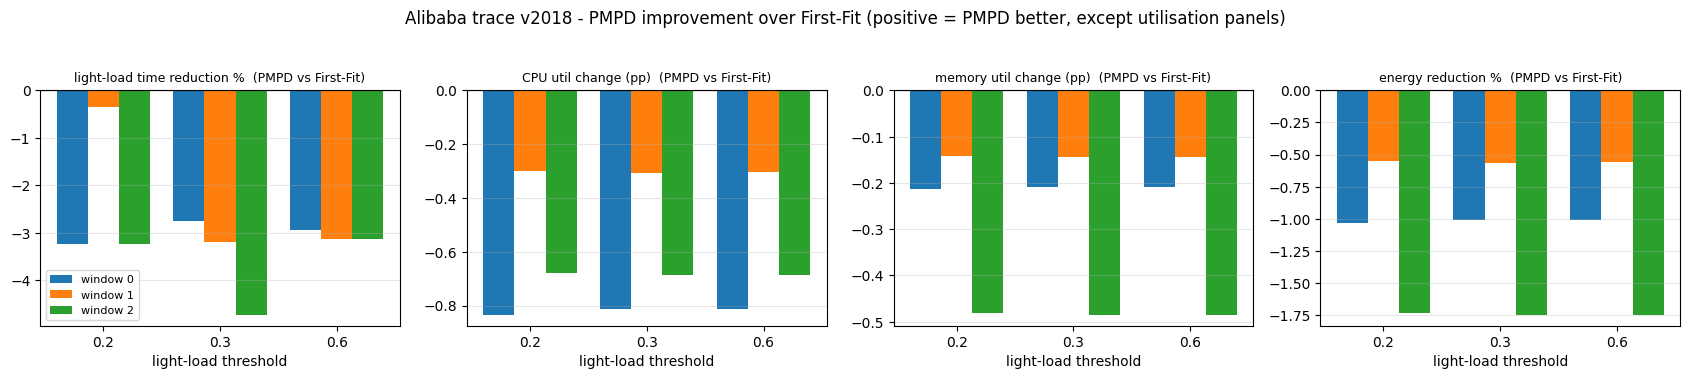

In [18]:
def peak_demand(vms):
    """Peak concurrent (cpu, mem) demand. At equal times releases are processed before arrivals, as in simulate()."""
    n = len(vms["arr"]); t = np.r_[vms["arr"], vms["arr"] + vms["dur"]]
    o = np.lexsort((np.r_[np.ones(n), np.zeros(n)], t))
    return [np.cumsum(np.r_[vms[k], -vms[k]][o]).max() for k in ("cpu", "mem")]

def calibrate_pool(vms, headroom=POOL_HEADROOM, grow=1.25, max_iter=15):
    """Start from peak demand x headroom, then enlarge until First-Fit places every VM."""
    pc, pm = peak_demand(vms)
    n = max(10, int(np.ceil(headroom * max(pc / PM_CPU, pm / PM_MEM))))
    for _ in range(max_iter):
        r = simulate(vms, np.full(n, PM_CPU), np.full(n, PM_MEM), FirstFit(), 0.6)
        if r["unplaced_vms"] == 0: return n, (pc, pm)
        n = int(np.ceil(n * grow))
    raise RuntimeError("could not size the pool so that First-Fit places every VM")

def run_real(vms, n_pms, thr):
    rows = []
    for pol in (FirstFit(), PMPD()):
        r = simulate(vms, np.full(n_pms, PM_CPU), np.full(n_pms, PM_MEM), pol, thr)
        r.update(algorithm=pol.name, threshold=thr, n_pms=n_pms); rows.append(r)
    return rows

real_cols = ["light_load_time_s", "avg_cpu_util", "avg_mem_util", "energy_kwh", "active_pm_hours", "peak_active_pms", "pms_used", "unplaced_vms", "acceptance_rate"]
if REAL_READY:
    real_runs, windows = [], {}
    for w, skip in enumerate(REAL_WINDOW_STARTS):
        vms = slice_window(real_all, skip, REAL_VMS_PER_WINDOW)
        if vms is None:
            print(f"window {w} (offset {skip:,}): too few VMs in the loaded rows - skipped"); continue
        t0 = time.time(); n_pms, (pc, pm) = calibrate_pool(vms); windows[w] = (vms, n_pms)
        print(f"window {w} | VMs {skip:,}-{skip+len(vms['arr']):,} | span {vms['arr'].max()/3600:.1f} h | peak demand {pc:.0f} cores, {pm:.0f} mem units -> pool {n_pms} PMs")
        for thr in REAL_THRS:
            for r in run_real(vms, n_pms, thr): r["window"] = w; real_runs.append(r)
        print(f"   done in {time.time()-t0:.0f}s")
    real_df = pd.DataFrame(real_runs)
    bad = real_df[real_df.unplaced_vms > 0]
    print("\nunplaced VMs in any run:", int(real_df.unplaced_vms.sum()), "(should be 0 - if not, raise POOL_HEADROOM)" if len(bad) else "")
    display(real_df.set_index(["window", "threshold", "algorithm"])[real_cols].round(3))

    imp = []
    for (w, thr), g in real_df.groupby(["window", "threshold"]):
        ff, pm = g[g.algorithm == "First-Fit"].iloc[0], g[g.algorithm == "PMPD"].iloc[0]
        imp.append({"window": w, "threshold": thr, "n_pms": int(ff.n_pms),
                    "light-load time reduction %": 100 * (ff.light_load_time_s - pm.light_load_time_s) / ff.light_load_time_s,
                    "CPU util change (pp)": 100 * (pm.avg_cpu_util - ff.avg_cpu_util),
                    "memory util change (pp)": 100 * (pm.avg_mem_util - ff.avg_mem_util),
                    "energy reduction %": 100 * (ff.energy_kwh - pm.energy_kwh) / ff.energy_kwh,
                    "active PM-hours reduction %": 100 * (ff.active_pm_hours - pm.active_pm_hours) / ff.active_pm_hours,
                    "peak active PMs (FF/PMPD)": f"{int(ff.peak_active_pms)}/{int(pm.peak_active_pms)}"})
    real_imp = pd.DataFrame(imp); display(real_imp.round(2).set_index(["window", "threshold"]))

    keys = ["light-load time reduction %", "CPU util change (pp)", "memory util change (pp)", "energy reduction %"]
    ws = sorted(real_df.window.unique()); width = 0.8 / len(ws)
    fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
    for ax, key in zip(axes, keys):
        for j, w in enumerate(ws):
            g = real_imp[real_imp.window == w]
            ax.bar(np.arange(len(g)) + j * width, g[key], width, label=f"window {w}")
        ax.axhline(0, color="k", lw=.8); ax.set_xticks(np.arange(len(REAL_THRS)) + width * (len(ws) - 1) / 2); ax.set_xticklabels(REAL_THRS)
        ax.set_xlabel("light-load threshold"); ax.set_title(key + "  (PMPD vs First-Fit)", fontsize=9); ax.grid(alpha=.3, axis="y")
    axes[0].legend(fontsize=8); fig.suptitle("Alibaba trace v2018 - PMPD improvement over First-Fit (positive = PMPD better, except utilisation panels)", y=1.04); plt.tight_layout(); plt.show()


window 0, threshold 0.3, base pool 41 PMs


n_pms  light_load_time_s  avg_cpu_util  avg_mem_util  energy_kwh  active_pm_hours  peak_active_pms  pms_used  unplaced_vms  \
pool_mult algorithm                                                                                                                               
0.6       First-Fit     25            35319.0         0.419         0.107       5.291           18.401               25        25          1349   
          PMPD          25            36300.0         0.410         0.105       5.344           18.770               25        25          1346   
0.7       First-Fit     29            35339.0         0.419         0.107       5.293           18.410               29        29           730   
          PMPD          29            36319.0         0.410         0.105       5.347           18.778               29        29           728   
0.8       First-Fit     33            35358.0         0.419         0.107       5.296           18.419               33        33           111   
          PMPD          33            36326.0         0.411         0.105       5.349           18.784               33        33           113   
0.9       First-Fit     37            35363.0         0.419         0.107       5.296           18.421               34        34             0   
          PMPD          37            36334.0         0.410         0.105       5.349           18.786               34        34             0   
1.0       First-Fit     41            35363.0         0.419         0.107       5.296           18.421               34        34             0   
          PMPD          41            36334.0         0.410         0.105       5.349           18.786               34        34             0   

                     acceptance_rate  
pool_mult algorithm                   
0.6       First-Fit            0.973  
          PMPD                 0.973  
0.7       First-Fit            0.985  
          PMPD                 0.985  
0.8       First-Fit            0.998  
          PMPD                 0.998  
0.9       First-Fit            1.000  
          PMPD                 1.000  
1.0       First-Fit            1.000  
          PMPD                 1.000

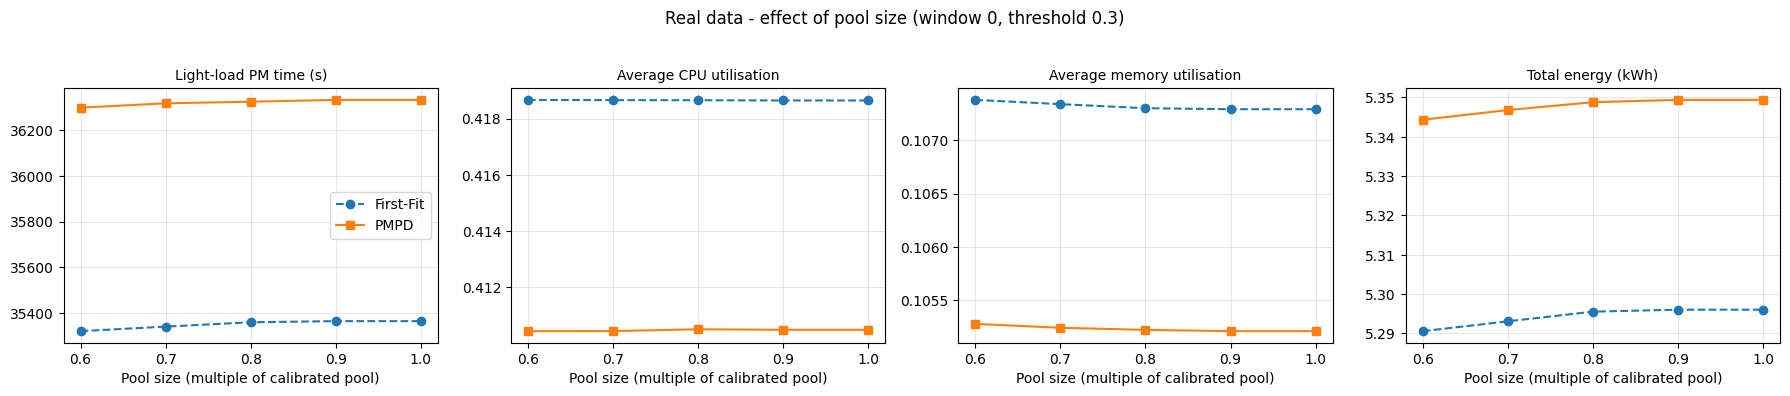

,light-load time reduction %,CPU util change (pp),memory util change (pp),energy reduction %
pool_mult,,,,
0.6,-2.78,-0.82,-0.21,-1.02
0.7,-2.77,-0.82,-0.21,-1.02
0.8,-2.74,-0.81,-0.21,-1.01
0.9,-2.75,-0.81,-0.21,-1.01
1.0,-2.75,-0.81,-0.21,-1.01


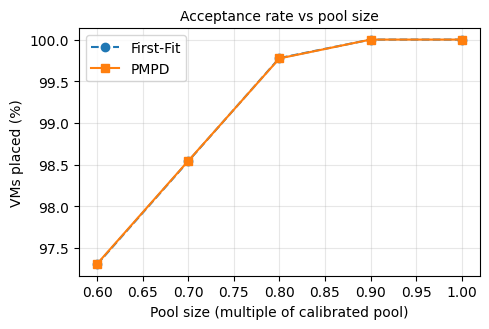

In [19]:
POOL_MULTS, SWEEP_THR = [0.6, 0.7, 0.8, 0.9, 1.0], 0.3
if REAL_READY and windows:
    w0 = min(windows); vms0, n_base = windows[w0]
    sweep = []
    for mult in POOL_MULTS:
        n = max(1, int(np.ceil(n_base * mult)))
        for r in run_real(vms0, n, SWEEP_THR): r["pool_mult"] = mult; sweep.append(r)
    pool_sweep = pd.DataFrame(sweep)
    print(f"window {w0}, threshold {SWEEP_THR}, base pool {n_base} PMs")
    display(pool_sweep.set_index(["pool_mult", "algorithm"])[["n_pms"] + real_cols].round(3))
    plot_sweep(pool_sweep, "pool_mult", "Pool size (multiple of calibrated pool)", f"Real data - effect of pool size (window {w0}, threshold {SWEEP_THR})")
    display(improvement(pool_sweep, "pool_mult"))
    fig, ax = plt.subplots(figsize=(5, 3.4))
    for alg, mk in (("First-Fit", "o--"), ("PMPD", "s-")):
        g = pool_sweep[pool_sweep.algorithm == alg]; ax.plot(g.pool_mult, 100 * g.acceptance_rate, mk, label=alg)
    ax.set_xlabel("Pool size (multiple of calibrated pool)"); ax.set_ylabel("VMs placed (%)"); ax.set_title("Acceptance rate vs pool size", fontsize=10); ax.grid(alpha=.3); ax.legend(); plt.tight_layout(); plt.show()


## 4. Notes for the report
- Compare **direction**, not exact percentages, with the paper: its CloudSim set-up, power model and durations are unpublished.
- State every assumption from the table at the top; state the real-data cleaning log and unit assumptions.
- Check `unplaced_vms == 0` in every run; if not, enlarge the PM pool before comparing algorithms.
- Scope items 5–6 (comparison with the paper's figures and the synthetic-vs-real discussion) are written up from these outputs.